**Note for reviewers.** This notebook also contains analyses that are not reported in the paper: role-centroid and distribution-matched controls. Unit-class results are reported. Those sections are kept only so the notebook runs as one unit, and their outputs should not be read as paper results.

# New wd=0.1 benchmark follow-up (execution preparation)
Exploratory validation analysis; historical saved outputs cleared.
Historical numerical prose is background, not a result of this benchmark.
Output-key scrubbing does not establish a serial algorithm. MB16 legacy scrub results
are invalidated by F25; use Section R corrected results. No new test access is permitted.


# MB17 — Are Identity and Context Separate *Inside* the Shared MLP Chain?

**Track B · Follow-up to MB05–MB16 · Identity × Context project**

| Item | Content |
|---|---|
| **Question** | MB06–MB14 found that the same four MLPs carry both the identity effect and the context effect. That is a statement about whole blocks. Inside those blocks, identity and context could still use **separate directions** (subspaces) of the residual stream, or separate hidden units. Are they separable at that finer grain, or do they share directions as well? |
| **Why it matters** | The paper's central negative claim ("no separate identity and context circuits") depends on it. If the two signals sit in near-orthogonal subspaces that can be removed one at a time, separate mechanisms exist inside shared MLPs and the claim must change. If they cannot be separated, the shared-computation reading becomes much stronger. |
| **Steps** | (1) the subspace spanned by each kind of change; (2) how much the identity and context subspaces overlap; (3) the causal test: remove one subspace and see which effect disappears; (4) whether single hidden units respond to identity, context, or both; (5) whether the player changes how context is processed; (6) whether, inside each MLP, an identity part writes towards a_id while the rest writes towards a_ctx; (7) a rule, written before results, for whether a sparse autoencoder is justified |
| **Population** | P-player validation. Subspaces and unit rankings are estimated on the **discovery** half; every causal number is measured on the **estimation** half. |
| **Status** | Follow-up after the deep MI audit; exploratory; not part of the MB12 lock. The plan is written and fingerprinted before any number. No test data. |
| **Outputs** | `config/MB17_plan.json`, `results/MB17_*`, `figures/MB17_*` |

In [1]:
import os
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: False | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.patching as patching
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, patching, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)
import warnings

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [3]:
verified_at_start = fingerprint.verify_files(MANIFEST)
manifest_before = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
assert IDENTITY == "player", "BLOCKED: MB14-MB16 follow up MB04-MB12, which studied the player variable."
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])


SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]
N_DRAWS = SETTINGS["n_draws"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
# No test view is built or read anywhere in MB14-MB16 (mi_setup.unlock_test_view is never called).
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
partners = pd.read_parquet(POP / "swap_partners.parquet")
donors = pd.read_parquet(POP / "context_donors.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
reference = torch.load(POP / "reference_means.pt", map_location="cpu", weights_only=False)
MEANS = {site: value.to(DEVICE) for site, value in reference["means"].items()}
REFERENCE_WINDOWS = np.asarray(reference["windows"])
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
ALL = circuits.all_components(N_LAYERS, N_HEADS)
FEATURES = list(bundle["encoded"].tensors.keys())
IDENTITY_FEATURES = [name for name in ["player", "team", "role", "competition"] if name in FEATURES]
CONTEXT_FEATURES = [name for name in FEATURES if name not in IDENTITY_FEATURES]

p_player = val_conflicts[val_conflicts.population == "P-player"].reset_index(drop=True)
p_player = p_player.merge(donors[["event_row", "donor_window"]], on="event_row", how="left")
discovery = p_player[p_player.half == "discovery"].reset_index(drop=True)
estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
index0 = val_conflicts[val_conflicts.population == "index-0"].reset_index(drop=True)
print(f"verified files: {len(verified_at_start)} | primary seed {PRIMARY_SEED} | seeds {SEEDS}")
print(f"P-player rows: {len(p_player):,} (discovery {len(discovery):,}, estimation {len(estimation):,}) | "
      f"index-0: {len(index0):,} | matched controls: {len(controls):,}")
print(f"components: {ALL}")
print(f"identity inputs: {IDENTITY_FEATURES} | context inputs ({len(CONTEXT_FEATURES)}): {CONTEXT_FEATURES}")

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 91 | primary seed 103 | seeds [100, 101, 102, 103, 104]
P-player rows: 1,744 (discovery 1,215, estimation 529) | index-0: 8,947 | matched controls: 252
components: ['L0H0', 'L0H1', 'L0MLP', 'L1H0', 'L1H1', 'L1MLP', 'L2H0', 'L2H1', 'L2MLP', 'L3H0', 'L3H1', 'L3MLP']
identity inputs: ['player', 'team', 'role', 'competition'] | context inputs (15): ['zone', 'period', 'minute_bin', 'score_diff', 'play_pattern', 'poss_len', 'possession_flag', 'prev_action', 'prev_outcome', 'prev_end_zone', 'same_player_as_prev', 'x_norm', 'y_norm', 'dt', 't_poss']


In [4]:
# Per-player facts from the TRAINING split, in the model's own (T300) player indices:
# modal role, modal team, number of training events. Used for frequency bands, role centroids and
# team-matched partners. Nothing here reads validation labels.
ENCODED = bundle["encoded"].tensors
assert len(ENCODED["player"]) == len(events), "BLOCKED: encoded tensors are not one row per event."
assert "split" in events.columns, "BLOCKED: events has no split column, so training counts cannot be computed."
TRAIN_ROWS = np.where(events["split"].to_numpy() == "train")[0]
_train = pd.DataFrame({name: ENCODED[name][torch.as_tensor(TRAIN_ROWS, device=ENCODED[name].device)].cpu().numpy()
                       for name in ["player", "role", "team"]})
_train = _train[_train["player"] > 0]
PLAYER_META = _train.groupby("player").agg(role=("role", lambda s: s.value_counts().index[0]),
                                           team=("team", lambda s: s.value_counts().index[0]),
                                           train_events=("role", "size"))
FREQUENCY_CUT = 1000


def frequency_band(players):
    counts = PLAYER_META["train_events"].reindex(np.asarray(players)).to_numpy()
    return np.where(np.isnan(counts), "no training events",
                    np.where(counts >= FREQUENCY_CUT, f">= {FREQUENCY_CUT} training events", f"< {FREQUENCY_CUT} training events"))


PLAYER_TABLE = MODEL.embedding.embeddings["player"].weight.detach()
ROLE_CENTROID = {int(role): PLAYER_TABLE[torch.as_tensor(group.index.to_numpy(), device=PLAYER_TABLE.device)].mean(0)
                 for role, group in PLAYER_META.groupby("role")}
print(f"players with training events: {len(PLAYER_META)} | roles: {len(ROLE_CENTROID)} | "
      f"frequency bands: {pd.Series(frequency_band(PLAYER_META.index)).value_counts().to_dict()}")


def player_vector_edit(new_vectors, players, positions):
    """Edit for site factor_player: at the scored position, swap the player's own embedding for new_vectors.

    The factor site is the sum of the group's embeddings; subtracting the player's own row and adding the new
    vector changes only the player part, whatever else the group contains."""
    own = PLAYER_TABLE[torch.as_tensor(np.asarray(players), device=PLAYER_TABLE.device)]

    def edit(value):
        new = value.clone()
        rows = torch.arange(len(positions), device=value.device)
        new[rows, positions] = value[rows, positions] - own.to(value.device) + new_vectors.to(value.device)
        return new
    return edit


def control_vectors(players, kind, rng):
    """Replacement player vectors for the identity controls (rows whose control is undefined get NaN)."""
    players = np.asarray(players)
    out = torch.full((len(players), PLAYER_TABLE.shape[1]), float("nan"), device=PLAYER_TABLE.device)
    for i, player in enumerate(players):
        if player not in PLAYER_META.index:
            continue
        role = int(PLAYER_META.loc[player, "role"])
        centroid = ROLE_CENTROID[role]
        own = PLAYER_TABLE[player]
        if kind == "role centroid":
            out[i] = centroid
        elif kind == "distribution-matched deviation":
            others = PLAYER_META.index[(PLAYER_META["role"] == role) & (PLAYER_META.index != player)
                                       & (PLAYER_META.index != partner_of.get(player, -1))].to_numpy()
            if len(others) == 0:
                continue
            other = PLAYER_TABLE[int(rng.choice(others))] - centroid
            out[i] = centroid + other * (own - centroid).norm() / (other.norm() + 1e-12)
        elif kind == "shuffled coordinates":
            out[i] = own[torch.as_tensor(rng.permutation(len(own)), device=own.device)]
        else:
            raise ValueError(kind)
    return out


def team_matched_partner(player):
    """Same modal role AND team, nearest log training count; -1 if none."""
    if player not in PLAYER_META.index:
        return -1
    row = PLAYER_META.loc[player]
    pool = PLAYER_META[(PLAYER_META["role"] == row["role"]) & (PLAYER_META["team"] == row["team"])
                       & (PLAYER_META.index != player)]
    if len(pool) == 0:
        return -1
    gap = np.abs(np.log(pool["train_events"].to_numpy()) - np.log(row["train_events"]))
    return int(pool.index[np.lexsort((pool.index.to_numpy(), gap))[0]])

players with training events: 350 | roles: 23 | frequency bands: {'< 1000 training events': 333, '>= 1000 training events': 17}


## 1. Terms

| Term | Meaning here |
|---|---|
| **Difference vector** | For one event and one edit, the activation at the scored position in the intact run minus the activation in the edited run. It shows where in activation space that edit moves the event. |
| **Subspace of an edit** | The top-r directions (uncentred SVD) of the stack of that edit's difference vectors on the discovery half. Uncentred, so the average change direction is included. |
| **Effective dimension** | Participation ratio (Σλ)² / Σλ² of the squared singular values: about 1 if every change points the same way, about d if changes are spread evenly. |
| **Overlap** | Mean squared cosine of the principal angles between two rank-r subspaces: 0 = orthogonal, 1 = the same subspace. Two random r-dimensional subspaces of a d-dimensional space have expected overlap r/d. |
| **Projection ablation** | At one residual point and the scored position, the activation's component in a subspace is set to its discovery-half mean: x ← x − U Uᵀ (x − μ). Everything else is untouched. |
| **Retained share** | Pooled, sign-aligned (effect with the projection) / (effect intact), estimation half. 1 = the projection did not touch the effect; 0 = it removed it. |
| **Identity effect / context effect / interaction** | Removal effect Δ(player) − Δ(player removed); whole-context effect Δ(own window) − Δ(donor window with **all four identity inputs** written back, which fixes MB06's team and competition contamination); interaction = identity effect in the own window minus identity effect in the donor window. |

## 2. The plan (written before any number)

In [5]:
PLAN = {
    "status": "follow-up after the deep MI audit; exploratory; not part of the MB12 lock",
    "points": "resid_pre_0, resid_post_0..3 and mlp_hidden_0..3, at the scored position",
    "edits": ["player removal", "player swap (matched partner)", "role swap (a role value of another role, seed 0)",
              "previous action, possession change and time gap: each set to the MB02 donor's value",
              "whole context with all four identity inputs written back", "norm-matched random player vector",
              "distribution-matched player vector"],
    "identity_subspace": "top-r uncentred SVD of the stacked player-removal and player-swap difference vectors (discovery)",
    "context_subspace": "top-r uncentred SVD of the whole-context difference vectors (discovery)",
    "overlap_baselines": ["norm-matched random-vector subspace vs the context subspace", "random r-dimensional subspaces (200 draws)"],
    "overlap_reading": "(rank 4, the only rank with match-resampled intervals) identity and context overlap beyond chance at a point if the identity-context overlap CI low exceeds the 95th percentile of random subspaces AND the random-vector-context overlap",
    "projection_ranks": [1, 2, 4, 8, "r90: for each subspace, the smallest rank holding 90 per cent of its edit's squared change (capped at half the width); random controls get the larger of the two ranks"],
    "projection_subspaces": ["identity", "context", "random-vector perturbation", "random (seed 0)"],
    "projection_reading": ("at a point and rank: SEPARABLE if removing the identity subspace retains <= 0.5 of the identity effect and >= 0.8 of the "
                           "context effect, removing the context subspace retains <= 0.5 of the context effect and >= 0.8 of the identity effect, "
                           "and the random subspace retains >= 0.8 of both; SHARED if either subspace retains <= 0.5 of both effects; otherwise MIXED"),
    "units": ("eta-squared of every MLP hidden unit for identity variables (player within role, role, team) and context variables "
              "(previous action, previous outcome, possession change, time gap quintile, x third, coupled flag, score difference, minute bin); "
              "threshold per variable = 99th percentile of eta-squared with labels shuffled (20 shuffles); all P-player validation events"),
    "unit_classes": {"A": "identity only", "B": "context only", "C": "identity and context", "D": "neither beyond the shuffled threshold",
                     "E": "identity and at least 3 context variables (broadly mixed)"},
    "top_units": "20 per layer with the largest |mean attribution| of the identity effect: (h - h_removed) x dDelta/dh, discovery half",
    "identity_conditioned_context": "cosine and norm ratio of the context-induced difference vector with player A vs with partner B, and vs a fixed norm-matched random vector",
    "mlp_split": "each MLP's output at the scored position split into its part in the rank-4 identity subspace of that layer and the rest; direct logit attribution of each part to Delta (final LayerNorm scale frozen); random rank-4 split as baseline",
    "sae_rule": ("an SAE is justified only if ALL hold: (i) more than half of the top identity-effect units are class C or E; "
                 "(ii) identity and context overlap beyond chance (overlap_reading) at one or more resid_post points; "
                 "(iii) projection is not SEPARABLE at any resid_post point and rank")
}
plan_path = OUT / "config" / "MB17_plan.json"
if plan_path.exists():
    stored = mi_setup.load_json(plan_path)
    changed = {key for key in PLAN if key != "written_at" and stored.get(key) != PLAN[key]}
    if changed:
        raise RuntimeError(f"BLOCKED: the plan in {plan_path.name} differs from this notebook in {sorted(changed)}. "
                           "A plan is written once, before results; delete the file only if no result was read.")
    PLAN = stored
    print("plan already written at", stored["written_at"], "- unchanged")
else:
    PLAN["written_at"] = fingerprint.now()
    mi_setup.save_json(plan_path, PLAN)
    print("plan written:", plan_path.name)
fingerprint.record_files(MANIFEST, {"config/MB17_plan.json": plan_path})
print(json.dumps({key: value for key, value in PLAN.items() if key != "written_at"}, indent=1))

plan written: MB17_plan.json
{
 "status": "follow-up after the deep MI audit; exploratory; not part of the MB12 lock",
 "points": "resid_pre_0, resid_post_0..3 and mlp_hidden_0..3, at the scored position",
 "edits": [
  "player removal",
  "player swap (matched partner)",
  "role swap (a role value of another role, seed 0)",
  "previous action, possession change and time gap: each set to the MB02 donor's value",
  "whole context with all four identity inputs written back",
  "norm-matched random player vector",
  "distribution-matched player vector"
 ],
 "identity_subspace": "top-r uncentred SVD of the stacked player-removal and player-swap difference vectors (discovery)",
 "context_subspace": "top-r uncentred SVD of the whole-context difference vectors (discovery)",
 "overlap_baselines": [
  "norm-matched random-vector subspace vs the context subspace",
  "random r-dimensional subspaces (200 draws)"
 ],
 "overlap_reading": "(rank 4, the only rank with match-resampled intervals) identi

## 3. Step 1 — Difference vectors and the subspace of each edit

In [6]:
RESID_POINTS = ["resid_pre_0"] + [f"resid_post_{l}" for l in range(N_LAYERS)]
HIDDEN_POINTS = [f"mlp_hidden_{l}" for l in range(N_LAYERS)]
POINTS = RESID_POINTS + HIDDEN_POINTS
SINGLE_FACTORS = [name for name in ["prev_action", "possession_flag", "dt"] if name in FEATURES]
print("single context inputs available:", SINGLE_FACTORS)
ROLES = np.array(sorted(ROLE_CENTROID))
usable = p_player[p_player["donor_window"].notna()].reset_index(drop=True)
usable["donor_window"] = usable["donor_window"].astype(int)
usable["partner"] = [partner_of.get(p, -1) for p in usable["player"]]
usable = usable[usable["partner"] > 0].reset_index(drop=True)
disc = usable[usable.half == "discovery"].reset_index(drop=True)
est = usable[usable.half == "estimation"].reset_index(drop=True)
print(f"events with a donor and a partner: discovery {len(disc)}, estimation {len(est)}")


def edited_inputs(kind, inputs, positions, chunk, rng, generator):
    """(inputs, replace) for one edit; replace is a dict for embedding-level edits."""
    rows = torch.arange(len(positions), device=DEVICE)
    own = chunk["player"].to_numpy()
    if kind == "player removal":
        return interventions.remove_feature(inputs, IDENTITY, positions), None
    if kind == "player swap":
        return interventions.set_feature(inputs, "player", positions, torch.as_tensor(chunk["partner"].to_numpy(), device=DEVICE)), None
    if kind == "role swap":
        current = inputs["role"][rows, positions].cpu().numpy()
        other = np.array([rng.choice(ROLES[ROLES != value]) if (ROLES != value).any() else value for value in current])
        return interventions.set_feature(inputs, "role", positions, torch.as_tensor(other, device=DEVICE)), None
    if kind in SINGLE_FACTORS:
        donor, _ = mi_setup.window_inputs(bundle, val_view, chunk["donor_window"].to_numpy())
        return interventions.set_feature(inputs, kind, positions, donor[kind][rows, positions]), None
    if kind == "whole context":
        donor, _ = mi_setup.window_inputs(bundle, val_view, chunk["donor_window"].to_numpy())
        return interventions.write_identity(donor, inputs, positions, IDENTITY_FEATURES), None
    if kind == "random player vector":
        return inputs, {"factor_player": interventions.norm_matched_vector(None, positions, generator)}
    if kind == "distribution-matched player":
        vectors = control_vectors(own, "distribution-matched deviation", rng)
        vectors = torch.where(torch.isnan(vectors), PLAYER_TABLE[torch.as_tensor(own, device=PLAYER_TABLE.device)], vectors)
        return inputs, {"factor_player": player_vector_edit(vectors, own, positions)}
    raise ValueError(kind)


EDITS = ["player removal", "player swap", "role swap"] + SINGLE_FACTORS + ["whole context", "random player vector", "distribution-matched player"]


@torch.no_grad()
def difference_vectors(table, seed=0):
    rng = np.random.default_rng(seed)
    generator = torch.Generator().manual_seed(seed)
    out = {(edit, point): [] for edit in EDITS for point in POINTS}
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        rows = torch.arange(len(positions), device=DEVICE)
        _, clean = hooks.forward(MODEL, inputs, capture=POINTS)
        for edit in EDITS:
            changed, replace = edited_inputs(edit, inputs, positions, chunk, rng, generator)
            _, cache = hooks.forward(MODEL, changed, capture=POINTS, replace=replace)
            for point in POINTS:
                out[(edit, point)].append((clean[point][rows, positions] - cache[point][rows, positions]).cpu().numpy())
    return {key: np.concatenate(values) for key, values in out.items()}


DIFF = difference_vectors(disc)


def subspace(matrix, rank):
    matrix = matrix[np.linalg.norm(matrix, axis=1) > 1e-8]
    _, values, vectors = np.linalg.svd(matrix, full_matrices=False)
    return vectors[:rank], values ** 2


def identity_matrix(diff, point):
    return np.vstack([diff[("player removal", point)], diff[("player swap", point)]])


dimension_rows = []
for point in POINTS:
    for edit in EDITS + ["identity (removal + swap)"]:
        matrix = identity_matrix(DIFF, point) if edit.startswith("identity") else DIFF[(edit, point)]
        nonzero = np.linalg.norm(matrix, axis=1) > 1e-8
        if nonzero.sum() < 5:
            continue
        _, energy = subspace(matrix, 1)
        share = np.cumsum(energy) / energy.sum()
        dimension_rows.append({"point": point, "edit": edit, "events changed": int(nonzero.sum()),
                               "mean norm of the change": float(np.linalg.norm(matrix[nonzero], axis=1).mean()),
                               "effective dimension": float(energy.sum() ** 2 / (energy ** 2).sum()),
                               **{f"variance in top {k}": float(share[min(k, len(share)) - 1]) for k in [1, 2, 4, 8]}})
dimensions = pd.DataFrame(dimension_rows)
dimensions.to_csv(OUT / "results" / "MB17_dimensions.csv", index=False)
print(dimensions.pivot(index="edit", columns="point", values="effective dimension").round(2).to_string())
print()
print(dimensions.pivot(index="edit", columns="point", values="variance in top 4").round(3).to_string())

single context inputs available: ['prev_action', 'possession_flag', 'dt']
events with a donor and a partner: discovery 1187, estimation 529


point                        mlp_hidden_0  mlp_hidden_1  mlp_hidden_2  mlp_hidden_3  resid_post_0  resid_post_1  resid_post_2  resid_post_3  resid_pre_0
edit                                                                                                                                                    
distribution-matched player         47.09         26.48         17.47         12.29         26.99         20.66         17.00          9.53        44.61
dt                                   1.99          1.98          2.62          4.74          1.33          1.99          4.00          4.17         1.00
identity (removal + swap)           42.03         25.39         17.96         12.75         24.89         19.43         16.20          9.92        34.21
player removal                      39.49         23.57         15.93         12.15         23.91         18.18         15.23          9.53        31.58
player swap                         36.72         24.04         18.15         12.7

**How to read it.** A small effective dimension for the identity edits *and* for the random-vector edit means the low rank is a property of how the network responds to any perturbation of that input, not of identity (MB11c's finding at the final layer). Look for points where the identity edits are lower-dimensional than the random-vector edit.

## 4. Step 2 — How much do the identity and context subspaces overlap?

                                              2             6             10            14            18            22            26            30            34
point                                resid_pre_0  resid_post_0  resid_post_1  resid_post_2  resid_post_3  mlp_hidden_0  mlp_hidden_1  mlp_hidden_2  mlp_hidden_3
rank                                           4             4             4             4             4             4             4             4             4
dimension                                    128           128           128           128           128           512           512           512           512
overlap identity vs context                0.021         0.132         0.283         0.358         0.636         0.093         0.283         0.486         0.513
CI low                                     0.019         0.079         0.161         0.265         0.574         0.047         0.223         0.381         0.436
CI high                           

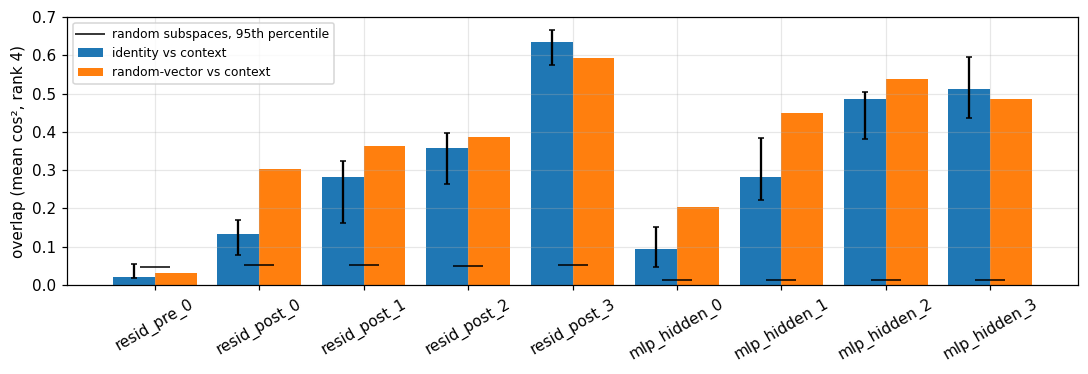

In [7]:
def overlap(a, b):
    """Mean squared cosine of the principal angles between the row spaces of a and b (orthonormal rows)."""
    cosines = np.linalg.svd(a @ b.T, compute_uv=False)
    return float(np.mean(cosines ** 2))


RANKS = [1, 2, 4, 8]
N_OVERLAP_BOOT = min(N_BOOT, 200)
rng = np.random.default_rng(0)
disc_matches = disc["match_id"].to_numpy()
unique_disc = np.unique(disc_matches)
rows_of = {m: np.where(disc_matches == m)[0] for m in unique_disc}
boot = [np.concatenate([rows_of[m] for m in rng.choice(unique_disc, len(unique_disc))]) for _ in range(N_OVERLAP_BOOT)]
overlap_rows = []
for point in POINTS:
    dim = DIFF[("player removal", point)].shape[1]
    for rank in RANKS:
        u_id, _ = subspace(identity_matrix(DIFF, point), rank)
        u_ctx, _ = subspace(DIFF[("whole context", point)], rank)
        u_rand_vec, _ = subspace(DIFF[("random player vector", point)], rank)
        random_draws = [overlap(np.linalg.qr(rng.standard_normal((dim, rank)))[0].T, u_ctx) for _ in range(200)]
        draws = []
        for rows in (boot if rank == 4 else []):
            sub = {key: value[rows] for key, value in DIFF.items() if key[1] == point}
            draws.append(overlap(subspace(identity_matrix(sub, point), rank)[0], subspace(sub[("whole context", point)], rank)[0]))
        row = {"point": point, "rank": rank, "dimension": dim,
               "overlap identity vs context": overlap(u_id, u_ctx),
               "CI low": float(np.percentile(draws, 2.5)) if draws else np.nan,
               "CI high": float(np.percentile(draws, 97.5)) if draws else np.nan,
               "overlap random-vector vs context": overlap(u_rand_vec, u_ctx),
               "overlap identity vs random-vector": overlap(u_id, u_rand_vec),
               "random subspaces: expected (r/d)": rank / dim,
               "random subspaces: 95th percentile": float(np.percentile(random_draws, 95))}
        for factor in SINGLE_FACTORS:
            row[f"overlap identity vs {factor}"] = overlap(u_id, subspace(DIFF[(factor, point)], rank)[0])
        row["overlap beyond chance (plan rule)"] = bool(row["CI low"] > row["random subspaces: 95th percentile"]
                                                       and row["CI low"] > row["overlap random-vector vs context"]) if draws else None
        overlap_rows.append(row)
overlaps = pd.DataFrame(overlap_rows)
overlaps.to_csv(OUT / "results" / "MB17_overlap.csv", index=False)
print(overlaps[overlaps["rank"] == 4].round(3).T.to_string())

fig, axis = plt.subplots(figsize=(10, 3.5))
block = overlaps[overlaps["rank"] == 4]
x = np.arange(len(block))
axis.bar(x - 0.2, block["overlap identity vs context"], 0.4, yerr=[block["overlap identity vs context"] - block["CI low"],
         block["CI high"] - block["overlap identity vs context"]], capsize=2, label="identity vs context")
axis.bar(x + 0.2, block["overlap random-vector vs context"], 0.4, label="random-vector vs context")
axis.plot(x, block["random subspaces: 95th percentile"], "k_", markersize=20, label="random subspaces, 95th percentile")
axis.set_xticks(x); axis.set_xticklabels(block["point"], rotation=30); axis.set_ylabel("overlap (mean cos², rank 4)")
axis.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB17_overlap.png", bbox_inches="tight"); plt.show()

**Caution.** Overlap is correlational. Two subspaces can overlap because both edits move the residual along the few directions the network uses for any change (the random-vector baseline checks this), and they can be orthogonal yet be read by the same downstream units. Step 3 is the causal test.

## 5. Step 3 — Remove one subspace: which effect disappears?

At each residual point and rank, the projection ablation is applied in **all four runs** of the 2 × 2 (own / donor window × player / player removed), so the identity effect, the context effect and the interaction are all measured under the same edit. Subspaces come from the discovery half; effects are measured on the estimation half.

**Ranks.** A fixed small rank can be too small: if player differences spread over many directions, removing 8 of them leaves most of the identity effect, whatever the mechanism. The rank "r90" therefore gives each subspace as many directions as it needs to hold 90% of its edit's change. Read the r90 column first; the fixed ranks show how the answer changes with size.

**The embedding row as a reference.** At `resid_pre_0` no layer has mixed anything yet: the player vector and the context vectors are simply added. They still share the same 128 dimensions, so even here they need not be separable by projection. The embedding row is therefore not a positive control. It is the starting point: if identity and context are SEPARABLE at the embedding but SHARED after L1, the layers mix them; if they are already MIXED at the embedding, the projection test cannot separate them at this width, and later verdicts mean less.

In [8]:
@torch.no_grad()
def point_means(table, points):
    totals = {point: 0.0 for point in points}
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        _, cache = hooks.forward(MODEL, inputs, capture=points)
        rows = torch.arange(len(positions), device=DEVICE)
        for point in points:
            totals[point] = totals[point] + cache[point][rows, positions].sum(0)
    return {point: (totals[point] / len(table)).cpu().numpy() for point in points}


POINT_MEAN = point_means(disc, POINTS)


def projection_edit(basis, mean, positions):
    basis_t = torch.as_tensor(basis, dtype=torch.float32, device=DEVICE)
    mean_t = torch.as_tensor(mean, dtype=torch.float32, device=DEVICE)

    def edit(value):
        new = value.clone()
        rows = torch.arange(len(positions), device=value.device)
        x = value[rows, positions]
        new[rows, positions] = x - ((x - mean_t) @ basis_t.T) @ basis_t
        return new
    return edit


@torch.no_grad()
def four_runs(table, replace_builder=None):
    """Delta in the four cells (own/donor window x player/removed), optionally under an edit built per batch."""
    out = {cell: np.empty(len(table)) for cell in ["own", "own removed", "donor", "donor removed"]}
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        donor, _ = mi_setup.window_inputs(bundle, val_view, chunk["donor_window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        a_ctx = torch.as_tensor(chunk["a_ctx"].to_numpy(), device=DEVICE)
        a_id = torch.as_tensor(chunk["a_id"].to_numpy(), device=DEVICE)
        donor = interventions.write_identity(donor, inputs, positions, IDENTITY_FEATURES)
        replace = replace_builder(positions) if replace_builder is not None else None
        for cell, cell_inputs in [("own", inputs), ("own removed", interventions.remove_feature(inputs, IDENTITY, positions)),
                                  ("donor", donor), ("donor removed", interventions.remove_feature(donor, IDENTITY, positions))]:
            out[cell][part] = circuits.delta_under(MODEL, cell_inputs, positions, a_ctx, a_id, replace)
    return out


def effects(runs):
    return {"identity effect": runs["own"] - runs["own removed"], "context effect": runs["own"] - runs["donor"],
            "interaction": (runs["own"] - runs["own removed"]) - (runs["donor"] - runs["donor removed"])}


intact_runs = four_runs(est)
intact = effects(intact_runs)
est_matches = est["match_id"].to_numpy()
for name, values in intact.items():
    summary = mi_metrics.summarise(values, est_matches, N_BOOT)
    print(f"intact {name:16s} mean {summary['mean']:+.4f} [{summary['ci_low']:+.4f}, {summary['ci_high']:+.4f}] | mean |.| {np.abs(values).mean():.4f}")

def rank_for_variance(matrix, share=0.9):
    """Smallest rank whose top directions hold `share` of the edit's squared change (uncentred), capped at half the width."""
    _, energy = subspace(matrix, 1)
    return int(min(np.searchsorted(np.cumsum(energy) / energy.sum(), share) + 1, matrix.shape[1] // 2))


PROJECTION_RANKS = [1, 2, 4, 8, "r90"]
projection_rows = []
start = time.time()
for point in RESID_POINTS:
    dim = DIFF[("player removal", point)].shape[1]
    r_id, r_ctx = rank_for_variance(identity_matrix(DIFF, point)), rank_for_variance(DIFF[("whole context", point)])
    for rank in PROJECTION_RANKS:
        k_id, k_ctx = (r_id, r_ctx) if rank == "r90" else (rank, rank)
        k_random = max(k_id, k_ctx)
        bases = {"identity": subspace(identity_matrix(DIFF, point), k_id)[0],
                 "context": subspace(DIFF[("whole context", point)], k_ctx)[0],
                 "random-vector perturbation": subspace(DIFF[("random player vector", point)], k_id)[0],
                 "random": np.linalg.qr(np.random.default_rng(k_random).standard_normal((dim, k_random)))[0].T}
        for name, basis in bases.items():
            runs = four_runs(est, lambda positions, b=basis, p=point: {p: projection_edit(b, POINT_MEAN[p], positions)})
            projected = effects(runs)
            row = {"point": point, "rank": str(rank), "dimensions removed": int(basis.shape[0]), "subspace removed": name,
                   "mean |change in Delta| (own window, player present)": float(np.abs(runs["own"] - intact_runs["own"]).mean())}
            for effect_name in ["identity effect", "context effect", "interaction"]:
                result = mi_metrics.pooled_recovery(projected[effect_name], intact[effect_name], est_matches, N_BOOT)
                row[f"{effect_name} retained"] = result["recovery"]
                row[f"{effect_name} CI low"], row[f"{effect_name} CI high"] = result["ci_low"], result["ci_high"]
            projection_rows.append(row)
print(f"projection ablations in {time.time() - start:.0f} s")
projections = pd.DataFrame(projection_rows)


def verdict(block):
    get = lambda subspace_name, effect: float(block.loc[block["subspace removed"] == subspace_name, f"{effect} retained"].iloc[0])
    separable = (get("identity", "identity effect") <= 0.5 and get("identity", "context effect") >= 0.8
                 and get("context", "context effect") <= 0.5 and get("context", "identity effect") >= 0.8
                 and get("random", "identity effect") >= 0.8 and get("random", "context effect") >= 0.8)
    shared = ((get("identity", "identity effect") <= 0.5 and get("identity", "context effect") <= 0.5)
              or (get("context", "identity effect") <= 0.5 and get("context", "context effect") <= 0.5))
    return "SEPARABLE" if separable else ("SHARED" if shared else "MIXED")


verdicts = pd.DataFrame([{"point": point, "rank": rank, "verdict (plan rule)": verdict(block)}
                         for (point, rank), block in projections.groupby(["point", "rank"])])
projections.to_csv(OUT / "results" / "MB17_projection.csv", index=False)
verdicts.to_csv(OUT / "results" / "MB17_projection_verdicts.csv", index=False)
print(projections.round(3).to_string(index=False))
print()
print(verdicts.pivot(index="point", columns="rank", values="verdict (plan rule)").loc[RESID_POINTS, [str(r) for r in PROJECTION_RANKS]].to_string())

intact identity effect  mean -0.1672 [-0.2647, -0.0558] | mean |.| 0.4687
intact context effect   mean +6.2668 [+5.9813, +6.6267] | mean |.| 6.5276
intact interaction      mean -0.1116 [-0.2035, -0.0152] | mean |.| 0.6178


projection ablations in 20 s
       point rank  dimensions removed           subspace removed  mean |change in Delta| (own window, player present)  identity effect retained  identity effect CI low  identity effect CI high  context effect retained  context effect CI low  context effect CI high  interaction retained  interaction CI low  interaction CI high
 resid_pre_0    1                   1                   identity                                                0.139                     0.995                   0.981                    1.024                    1.002                  0.994                   1.009                 0.997               0.980                1.016
 resid_pre_0    1                   1                    context                                                5.367                     0.357                   0.258                    0.523                    0.477                  0.410                   0.540                 0.260               0.169         

**How to read it.** In each row, the retained shares say what removing that subspace did to each effect; "mean |change in Δ|" shows how much the projection disturbs the model overall. The verdict table applies the plan's rule at every point and rank. Compare each point with the embedding row: a change of verdict with depth is the finding.

## 6. Step 4 — Do single hidden units respond to identity, context, or both?

η² of each hidden unit's activation at the scored position, for each variable: the share of the unit's variance explained by the variable's groups. Variables with many values (the player has hundreds) get a high η² by chance, so each variable's threshold is the 99th percentile of η² with its labels shuffled. "Player within role" uses activations with the role means removed, so it measures player information beyond role.

In [9]:
@torch.no_grad()
def hidden_and_labels(table):
    acts = {point: [] for point in HIDDEN_POINTS}
    labels = {name: [] for name in ["player", "role", "team", "prev_action", "prev_outcome", "possession_flag", "dt",
                                    "x_norm", "score_diff", "minute_bin"] if name in FEATURES}
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        rows = torch.arange(len(positions), device=DEVICE)
        _, cache = hooks.forward(MODEL, inputs, capture=HIDDEN_POINTS)
        for point in HIDDEN_POINTS:
            acts[point].append(cache[point][rows, positions].cpu().numpy())
        for name in labels:
            labels[name].append(inputs[name][rows, positions].cpu().numpy())
    acts = {point: np.concatenate(values) for point, values in acts.items()}
    labels = {name: np.concatenate(values) for name, values in labels.items()}
    for name in ["dt", "x_norm"]:
        if name in labels:
            bins = 5 if name == "dt" else 3
            labels[name] = pd.qcut(labels[name], bins, labels=False, duplicates="drop")
    labels["coupled"] = (~table["genuine"].to_numpy().astype(bool)).astype(int)
    return acts, labels


def eta_squared(activations, groups):
    codes, inverse = np.unique(groups, return_inverse=True)
    counts = np.bincount(inverse).astype(float)
    sums = np.zeros((len(codes), activations.shape[1]))
    np.add.at(sums, inverse, activations)
    means = sums / counts[:, None]
    grand = activations.mean(0)
    between = (counts[:, None] * (means - grand) ** 2).sum(0)
    total = ((activations - grand) ** 2).sum(0) + 1e-12
    return between / total


def role_residual(activations, roles):
    codes, inverse = np.unique(roles, return_inverse=True)
    sums = np.zeros((len(codes), activations.shape[1]))
    np.add.at(sums, inverse, activations)
    return activations - (sums / np.bincount(inverse)[:, None])[inverse]


ACTS, LABELS = hidden_and_labels(p_player)
IDENTITY_VARIABLES = ["player within role", "role", "team"]
CONTEXT_VARIABLES = [name for name in LABELS if name not in ["player", "role", "team"]]
rng = np.random.default_rng(0)
unit_frames = []
for point in HIDDEN_POINTS:
    acts = ACTS[point]
    frame = pd.DataFrame({"point": point, "unit": np.arange(acts.shape[1])})
    for variable in IDENTITY_VARIABLES + CONTEXT_VARIABLES:
        if variable == "player within role":
            source, groups = role_residual(acts, LABELS["role"]), LABELS["player"]
        else:
            source, groups = acts, LABELS[variable]
        observed = eta_squared(source, groups)
        shuffled = np.concatenate([eta_squared(source, rng.permutation(groups)) for _ in range(20)])
        threshold = float(np.percentile(shuffled, 99))
        frame[variable] = observed
        frame[f"{variable} selective"] = observed > threshold
    frame["identity selective"] = frame[[f"{v} selective" for v in IDENTITY_VARIABLES]].any(axis=1)
    frame["context variables selective"] = frame[[f"{v} selective" for v in CONTEXT_VARIABLES]].sum(axis=1)
    frame["class"] = np.select([frame["identity selective"] & (frame["context variables selective"] >= 3),
                                frame["identity selective"] & (frame["context variables selective"] > 0),
                                frame["identity selective"], frame["context variables selective"] > 0],
                               ["E", "C", "A", "B"], default="D")
    unit_frames.append(frame)
units_table = pd.concat(unit_frames, ignore_index=True)
class_shares = units_table.groupby("point")["class"].value_counts(normalize=True).unstack(fill_value=0).loc[HIDDEN_POINTS]
print("share of ALL hidden units in each class (A identity only, B context only, C both, D neither, E identity + >= 3 context variables):")
print(class_shares.round(3).to_string())

share of ALL hidden units in each class (A identity only, B context only, C both, D neither, E identity + >= 3 context variables):
class             B      E
point                     
mlp_hidden_0  0.000  1.000
mlp_hidden_1  0.004  0.996
mlp_hidden_2  0.000  1.000
mlp_hidden_3  0.008  0.992


**Top identity-effect units.** Which units carry the identity effect? Attribution per unit: the mean, over discovery events, of (activation with the player − activation with the player removed) × ∂Δ/∂activation. The 20 units per layer with the largest |attribution| are classified.

In [10]:
def unit_attribution(table, point):
    totals = None
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        rows = torch.arange(len(positions), device=DEVICE)
        a_ctx = torch.as_tensor(chunk["a_ctx"].to_numpy(), device=DEVICE)
        a_id = torch.as_tensor(chunk["a_id"].to_numpy(), device=DEVICE)
        with torch.no_grad():
            _, removed = hooks.forward(MODEL, interventions.remove_feature(inputs, IDENTITY, positions), capture=[point])
        holder = {}

        def keep(value):
            leaf = value.detach().requires_grad_(True)
            holder["leaf"] = leaf
            return leaf
        with torch.enable_grad():
            logits, _ = hooks.forward(MODEL, inputs, replace={point: keep})
            target = mi_metrics.at_target(logits, positions)
            (target[rows, a_ctx] - target[rows, a_id]).sum().backward()
        leaf = holder["leaf"]
        contribution = ((leaf.detach()[rows, positions] - removed[point][rows, positions]) * leaf.grad[rows, positions]).sum(0)
        totals = contribution if totals is None else totals + contribution
    return (totals / len(table)).cpu().numpy()


top_rows = []
for point in HIDDEN_POINTS:
    attribution = unit_attribution(disc, point)
    top = np.argsort(-np.abs(attribution))[:20]
    block = units_table[(units_table.point == point) & units_table.unit.isin(top)].copy()
    block["attribution"] = attribution[block["unit"].to_numpy()]
    block["share of the layer's total |attribution|"] = np.abs(block["attribution"]) / np.abs(attribution).sum()
    top_rows.append(block)
top_units = pd.concat(top_rows, ignore_index=True)
top_units.to_csv(OUT / "results" / "MB17_top_units.csv", index=False)
units_table.to_csv(OUT / "results" / "MB17_units.csv", index=False)
top_classes = top_units.groupby("point")["class"].value_counts().unstack(fill_value=0).reindex(HIDDEN_POINTS).fillna(0)
print("class counts among the top-20 identity-effect units per layer:")
print(top_classes.to_string())
MIXED_SHARE = float(top_units["class"].isin(["C", "E"]).mean())
print(f"share of top identity-effect units that are class C or E: {MIXED_SHARE:.3f}")
print("share of each layer's |attribution| held by its top 20 units:",
      top_units.groupby("point")["share of the layer's total |attribution|"].sum().round(3).to_dict())

class counts among the top-20 identity-effect units per layer:
class         B   E
point              
mlp_hidden_0  0  20
mlp_hidden_1  1  19
mlp_hidden_2  0  20
mlp_hidden_3  0  20
share of top identity-effect units that are class C or E: 0.988
share of each layer's |attribution| held by its top 20 units: {'mlp_hidden_0': 0.25999999046325684, 'mlp_hidden_1': 0.3089999854564667, 'mlp_hidden_2': 0.28600001335144043, 'mlp_hidden_3': 0.27000001072883606}


## 7. Step 5 — Does the player change how the context is processed? (RQ9)

For each event: the context-induced change (own window minus donor window with identity written back) computed once with the event's own player A and once with the partner B written into both windows. If identity did not affect how context is processed, the two change vectors would be the same (cosine 1, norm ratio 1). The baseline B is a fixed norm-matched random vector (same in both windows), which shows how much *any* change to the player input bends the context change.

In [11]:
@torch.no_grad()
def context_change(table, second, seed=0):
    generator = torch.Generator().manual_seed(seed)
    out = {point: {"cos": [], "log ratio": []} for point in RESID_POINTS[1:] + HIDDEN_POINTS}
    points = list(out)
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        donor, _ = mi_setup.window_inputs(bundle, val_view, chunk["donor_window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        rows = torch.arange(len(positions), device=DEVICE)
        donor = interventions.write_identity(donor, inputs, positions, IDENTITY_FEATURES)
        _, own_a = hooks.forward(MODEL, inputs, capture=points)
        _, donor_a = hooks.forward(MODEL, donor, capture=points)
        if second == "partner":
            partner = torch.as_tensor(chunk["partner"].to_numpy(), device=DEVICE)
            _, own_b = hooks.forward(MODEL, interventions.set_feature(inputs, "player", positions, partner), capture=points)
            _, donor_b = hooks.forward(MODEL, interventions.set_feature(donor, "player", positions, partner), capture=points)
        else:
            direction = torch.randn((len(chunk), MODEL.ln_final.weight.shape[0]), generator=generator).to(DEVICE)
            direction = direction / direction.norm(dim=-1, keepdim=True)

            def fixed(value):
                new = value.clone()
                new[rows, positions] = direction * value[rows, positions].norm(dim=-1, keepdim=True)
                return new
            _, own_b = hooks.forward(MODEL, inputs, capture=points, replace={"factor_player": fixed})
            _, donor_b = hooks.forward(MODEL, donor, capture=points, replace={"factor_player": fixed})
        for point in points:
            change_a = (own_a[point] - donor_a[point])[rows, positions]
            change_b = (own_b[point] - donor_b[point])[rows, positions]
            cos = torch.nn.functional.cosine_similarity(change_a, change_b, dim=-1)
            ratio = torch.log((change_b.norm(dim=-1) + 1e-9) / (change_a.norm(dim=-1) + 1e-9))
            out[point]["cos"].append(cos.cpu().numpy())
            out[point]["log ratio"].append(ratio.cpu().numpy())
    return {point: {key: np.concatenate(values) for key, values in parts.items()} for point, parts in out.items()}


rq9_rows = []
for second in ["partner", "random vector"]:
    result = context_change(est, second)
    for point, parts in result.items():
        cos = mi_metrics.summarise(parts["cos"], est_matches, N_BOOT)
        ratio = mi_metrics.summarise(parts["log ratio"], est_matches, N_BOOT)
        rq9_rows.append({"point": point, "player B": second, "mean cosine (A vs B)": cos["mean"], "CI low": cos["ci_low"],
                         "CI high": cos["ci_high"], "mean log norm ratio B/A": ratio["mean"],
                         "ratio CI low": ratio["ci_low"], "ratio CI high": ratio["ci_high"]})
rq9 = pd.DataFrame(rq9_rows)
rq9.to_csv(OUT / "results" / "MB17_identity_conditioned_context.csv", index=False)
print(rq9.round(4).to_string(index=False))

       point      player B  mean cosine (A vs B)  CI low  CI high  mean log norm ratio B/A  ratio CI low  ratio CI high
resid_post_0       partner                0.9954  0.9947   0.9959                   0.0039       -0.0028         0.0118
resid_post_1       partner                0.9891  0.9876   0.9903                   0.0081       -0.0008         0.0182
resid_post_2       partner                0.9827  0.9790   0.9854                   0.0089       -0.0061         0.0250
resid_post_3       partner                0.9789  0.9722   0.9837                   0.0085       -0.0063         0.0233
mlp_hidden_0       partner                0.9827  0.9814   0.9834                   0.0047       -0.0056         0.0163
mlp_hidden_1       partner                0.9819  0.9793   0.9834                   0.0105       -0.0026         0.0247
mlp_hidden_2       partner                0.9785  0.9743   0.9814                   0.0107       -0.0065         0.0287
mlp_hidden_3       partner              

**How to read it.** A cosine close to 1 with the partner means the context change is processed almost the same way whoever the player is (the player does not gate context at that point). A cosine with the partner clearly *below* the random-vector cosine would mean that real player content bends the context processing more than an arbitrary change of the same size: identity-conditioned processing that is specific to learned players.

## 8. Step 6 — Inside each MLP: does an identity part write towards a_id while the rest writes towards a_ctx? (H5)

Each MLP's output at the scored position is split into its component in the rank-4 identity subspace of that layer's output point (`resid_post_l`) and the remainder, and each part's direct effect on Δ is read through the final LayerNorm (scale frozen at the intact run) and the unembedding. This is the **direct** path only: later layers also read the MLP's output. A random rank-4 subspace gives the baseline split.

In [12]:
W_U = MODEL.unembed.weight.detach()


@torch.no_grad()
def mlp_split(table, rank=4):
    rows_out = []
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        rows = torch.arange(len(positions), device=DEVICE)
        a_ctx = torch.as_tensor(chunk["a_ctx"].to_numpy(), device=DEVICE)
        a_id = torch.as_tensor(chunk["a_id"].to_numpy(), device=DEVICE)
        sites = ["final_resid"] + [f"mlp_out_{l}" for l in range(N_LAYERS)]
        _, cache = hooks.forward(MODEL, inputs, capture=sites)
        _, removed = hooks.forward(MODEL, interventions.remove_feature(inputs, IDENTITY, positions), capture=sites)
        scale = hooks.final_layernorm_scale(MODEL, cache["final_resid"])[rows, positions]
        readout = (W_U[a_ctx] - W_U[a_id]) * MODEL.ln_final.weight

        def dla(x):
            return ((x - x.mean(-1, keepdim=True)) * scale * readout).sum(-1).cpu().numpy()
        frame = {"match_id": chunk["match_id"].to_numpy()}
        for l in range(N_LAYERS):
            point = f"resid_post_{l}"
            bases = {"identity": subspace(identity_matrix(DIFF, point), rank)[0],
                     "random": np.linalg.qr(np.random.default_rng(100 + l).standard_normal((DIFF[("player removal", point)].shape[1], rank)))[0].T}
            for which, source in [("write", cache[f"mlp_out_{l}"][rows, positions]),
                                  ("identity-induced change", (cache[f"mlp_out_{l}"] - removed[f"mlp_out_{l}"])[rows, positions])]:
                frame[f"L{l} {which}: total"] = dla(source)
                for name, basis in bases.items():
                    b = torch.as_tensor(basis, dtype=torch.float32, device=DEVICE)
                    inside = (source @ b.T) @ b
                    frame[f"L{l} {which}: {name} part"] = dla(inside)
                    frame[f"L{l} {which}: rest after {name}"] = dla(source - inside)
        rows_out.append(pd.DataFrame(frame))
    return pd.concat(rows_out, ignore_index=True)


split = mlp_split(est)
split_rows = []
for l in range(N_LAYERS):
    for which in ["write", "identity-induced change"]:
        for name in ["identity", "random"]:
            inside, rest = split[f"L{l} {which}: {name} part"], split[f"L{l} {which}: rest after {name}"]
            summary_inside = mi_metrics.summarise(inside, split["match_id"], N_BOOT)
            summary_rest = mi_metrics.summarise(rest, split["match_id"], N_BOOT)
            split_rows.append({"MLP": f"L{l}", "what is split": which, "subspace": name,
                               "mean DLA total": float(split[f"L{l} {which}: total"].mean()),
                               "mean DLA of the part in the subspace": summary_inside["mean"],
                               "part CI low": summary_inside["ci_low"], "part CI high": summary_inside["ci_high"],
                               "mean DLA of the rest": summary_rest["mean"],
                               "share of events: part towards a_id AND rest towards a_ctx": float(((inside < 0) & (rest > 0)).mean())})
mlp_parts = pd.DataFrame(split_rows)
mlp_parts.to_csv(OUT / "results" / "MB17_mlp_split.csv", index=False)
print(mlp_parts.round(4).to_string(index=False))

MLP           what is split subspace  mean DLA total  mean DLA of the part in the subspace  part CI low  part CI high  mean DLA of the rest  share of events: part towards a_id AND rest towards a_ctx
 L0                   write identity          0.5405                                0.0350       0.0120        0.0568                0.5055                                                     0.2911
 L0                   write   random          0.5405                               -0.0031      -0.0060       -0.0003                0.5437                                                     0.4669
 L0 identity-induced change identity         -0.0194                               -0.0072      -0.0122        0.0006               -0.0122                                                     0.2136
 L0 identity-induced change   random         -0.0194                                0.0014      -0.0004        0.0035               -0.0208                                                     0.1229
 L1  

**How to read it.** H5 (an identity sub-mechanism inside the MLPs that pushes towards a_id, outvoted by the rest) predicts a clearly negative identity part and a positive rest, on more events than the random split gives. A small identity part with the same sign as the rest means the identity subspace simply carries a little of the same push.

## 9. Step 7 — Is a sparse autoencoder justified?

The rule was written in the plan before any number. All three conditions must hold.

In [13]:
later = overlaps[overlaps["point"].str.startswith("resid_post") & (overlaps["rank"] == 4)]
condition_ii = bool(later["overlap beyond chance (plan rule)"].any())
later_verdicts = verdicts[verdicts["point"].str.startswith("resid_post")]
condition_iii = bool((later_verdicts["verdict (plan rule)"] != "SEPARABLE").all())
condition_i = MIXED_SHARE > 0.5
embedding_verdicts = verdicts[verdicts.point == "resid_pre_0"].set_index("rank")["verdict (plan rule)"].to_dict()
decision = {"(i) more than half of the top identity-effect units are class C or E": condition_i,
            "share of top units in C or E": MIXED_SHARE,
            "(ii) identity-context overlap beyond chance at a resid_post point": condition_ii,
            "(iii) projection not SEPARABLE at any resid_post point and rank": condition_iii,
            "reference: verdicts at the embedding (before any layer)": embedding_verdicts,
            "SAE justified": bool(condition_i and condition_ii and condition_iii)}
if decision["SAE justified"]:
    best = later.sort_values("overlap identity vs context", ascending=False).iloc[0]
    decision["layer to train it on"] = best["point"]
print(json.dumps(decision, indent=1))
if embedding_verdicts.get("r90") != "SEPARABLE":
    print("NOTE: identity and context are not SEPARABLE by projection even at the embedding (r90). Condition (iii) then says little "
          "about what the layers do; compare the later verdicts with the embedding's rather than reading them alone.")

{
 "(i) more than half of the top identity-effect units are class C or E": true,
 "share of top units in C or E": 0.9875,
 "(ii) identity-context overlap beyond chance at a resid_post point": false,
 "(iii) projection not SEPARABLE at any resid_post point and rank": false,
 "reference: verdicts at the embedding (before any layer)": {
  "1": "SHARED",
  "2": "MIXED",
  "4": "MIXED",
  "8": "SHARED",
  "r90": "SHARED"
 },
 "SAE justified": false
}
NOTE: identity and context are not SEPARABLE by projection even at the embedding (r90). Condition (iii) then says little about what the layers do; compare the later verdicts with the embedding's rather than reading them alone.


## 10. Summary and integrity

In [14]:
summary = {"status": PLAN["status"], "dimensions": dimensions.to_dict(orient="records"),
           "overlap": overlaps.to_dict(orient="records"), "projection": projections.to_dict(orient="records"),
           "projection_verdicts": verdicts.to_dict(orient="records"),
           "unit_class_shares": class_shares.reset_index().to_dict(orient="records"),
           "top_unit_classes": top_classes.reset_index().to_dict(orient="records"),
           "identity_conditioned_context": rq9.to_dict(orient="records"), "mlp_split": mlp_parts.to_dict(orient="records"),
           "sae_decision": decision, "run_mode": RUN_MODE}
mi_setup.save_json(OUT / "results" / "MB17_summary.json", summary)
fingerprint.record_files(MANIFEST, {"results/MB17_summary.json": OUT / "results" / "MB17_summary.json"})
fingerprint.register(REGISTRY, {"notebook": "MB17", "experiment": "superposition and geometry of identity and context",
                                "seed": PRIMARY_SEED, "run_mode": RUN_MODE})
print(verdicts.pivot(index="point", columns="rank", values="verdict (plan rule)").loc[RESID_POINTS, [str(r) for r in PROJECTION_RANKS]].to_string())
print("SAE justified:", decision["SAE justified"])

rank               1          2       4       8     r90
point                                                  
resid_pre_0   SHARED      MIXED   MIXED  SHARED  SHARED
resid_post_0   MIXED      MIXED   MIXED   MIXED  SHARED
resid_post_1   MIXED      MIXED   MIXED   MIXED  SHARED
resid_post_2   MIXED      MIXED   MIXED  SHARED  SHARED
resid_post_3   MIXED  SEPARABLE  SHARED  SHARED  SHARED
SAE justified: False


In [15]:
verified_at_end = fingerprint.verify_files(MANIFEST)
manifest_after = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
changed = sorted(name for name in manifest_before if manifest_after.get(name) != manifest_before[name])
print(f"manifest entries verified at the end: {len(verified_at_end)}")
print("earlier entries whose fingerprint changed during this notebook:", changed if changed else "none")
assert not changed, "BLOCKED: an earlier Track B file changed while this notebook ran."
test_log = OUT / "logs" / "test_access_log.jsonl"
test_lines = len(test_log.read_text().strip().splitlines()) if test_log.exists() and test_log.read_text().strip() else 0
print(f"test accesses recorded so far: {test_lines} (MB12 recorded exactly one; this notebook adds none)")

manifest entries verified at the end: 93
earlier entries whose fingerprint changed during this notebook: none
test accesses recorded so far: 1 (MB12 recorded exactly one; this notebook adds none)


**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- What was observed:
- What it supports / contradicts:
- What it does not establish:
- Evidence label: